# Задача 1. Описова статистика та теорія ймовірностей: реальні дані (ceosal1)

[Умова завдання](task1-description.pdf).

Дослідіть дані про оплату праці виконавчих директорів (CEO) США та показники їхніх компаній:

- `salary` — річна заробітна плата разом із бонусами, тис. доларів США;
- `pcsalary` — відсоткова зміна заробітної плати порівняно з попереднім роком;
- `age` — вік CEO у роках, змодельований за розподілом $N(53, 6.5^2)$;
- `sales` — річний дохід компанії від продажів, млн доларів США;
- `roe` — рентабельність власного капіталу компанії, %.

Вік є синтетичним: його немає у вихідному наборі `ceosal1`. Висновки про зв'язок віку з іншими показниками стосуються змодельованих даних. Початкове значення генератора `SEED = 42` забезпечує відтворюваність. Дані завантажуються під час першого запуску та зберігаються локально в `data/`.


In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "requirements.txt").exists())
TASK_DIR = ROOT / "labs" / "task1"
DATA_DIR = TASK_DIR / "data"
FIGURES_DIR = TASK_DIR / "figures"
SEED = 42
rng = np.random.default_rng(SEED)
sns.set_theme(style="whitegrid")


In [2]:
from statsmodels.datasets import get_rdataset

cache = DATA_DIR / "ceosal1.csv"
if cache.exists():
    df = pd.read_csv(cache)
else:
    df = get_rdataset("ceosal1", "wooldridge").data
    df.to_csv(cache, index=False)

# Синтетичний вік, а не спостережувані дані. Скидаємо генератор для відтворюваності повторних запусків.
df["age"] = np.random.default_rng(SEED).normal(53, 6.5, size=len(df))
columns = ["salary", "pcsalary", "age", "sales", "roe"]
assert set(columns).issubset(df.columns)
df[columns].head()


,salary,pcsalary,age,sales,roe
0,1095,20,54.980661,27595.000000,14.1
1,1001,32,46.240103,9958.000000,10.9
2,1122,9,57.877933,6125.899902,23.5
3,578,-9,59.113671,16246.000000,5.9
4,1368,7,40.318271,21783.199219,13.8


## Частина 1(а). Міри положення

Для `salary` обчисліть середнє значення, 5%-усічене середнє, медіану, нижній і верхній квартилі та квантилі рівнів 0.05 і 0.95. Дайте економічну інтерпретацію кожного показника — щонайменше одне речення на показник. Зазначте, яку частку спостережень відкидаєте з кожного краю під час обчислення усіченого середнього.


In [3]:
salary = df["salary"].dropna()

# всього спостережень
n = len(salary)

proportiontocut = 0.05

# кількість спостережень, які треба відкинути з кожного краю вибірки
k = int(np.floor(proportiontocut * n))

mean_salary = salary.mean()
trimmed_mean_5 = stats.trim_mean(salary, proportiontocut=proportiontocut)
median_salary = salary.median()

q05 = salary.quantile(0.05)
q25 = salary.quantile(0.25)
q75 = salary.quantile(0.75)
q95 = salary.quantile(0.95)

results = pd.Series(
    {
        "Середнє": mean_salary,
        "5%-усічене середнє": trimmed_mean_5,
        "Нижній 5%-квантиль": q05,
        "Нижній квартиль (Q1)": q25,
        "Медіана": median_salary,
        "Верхній квартиль (Q3)": q75,
        "Верхній 5%-квантиль": q95,
    },
    name="Значення, тис. дол. США",
)

print(f"Кількість спостережень: n = {n}")
print(f"Для 5%-усіченого середнього відкидаємо {k} спостережень з кожного краю.")

results.to_frame().round(2)

Кількість спостережень: n = 209
Для 5%-усіченого середнього відкидаємо 10 спостережень з кожного краю.


,"Значення, тис. дол. США"
Середнє,1281.12
5%-усічене середнє,1100.88
Нижній 5%-квантиль,450.00
Нижній квартиль (Q1),736.00
Медіана,1039.00
Верхній квартиль (Q3),1407.00
Верхній 5%-квантиль,2295.40


### Інтерпретація

- **Середнє:** середня річна зарплата CEO у вибірці становить **1281.12 тис. дол. США**.

- **5%-усічене середнє:** після вилучення 10 найменших і 10 найбільших значень зарплати середнє становить **1100.88 тис. дол. США**. Воно нижче за звичайне середнє, отже дуже високі зарплати помітно збільшують середнє значення.

- **Медіана:** медіанна зарплата становить **1039 тис. дол. США**. Приблизно половина CEO має зарплату нижчу або рівну цьому значенню, а інша половина – вищу або рівну.

- **Нижній квартиль $Q_1$:** приблизно 25% CEO мають зарплату не більше **736 тис. дол. США**.

- **Верхній квартиль $Q_3$:** приблизно 75% CEO мають зарплату не більше **1407 тис. дол. США**, а близько 25% мають більшу зарплату.

- **5%-квантиль:** приблизно 5% CEO мають зарплату не більше **450 тис. дол. США**.

- **95%-квантиль:** приблизно 95% CEO мають зарплату не більше **2295.40 тис. дол. США**, а близько 5% мають більшу зарплату.

Звичайне середнє (**1281.12**) помітно вище за медіану (**1039**) і 5%-усічене середнє (**1100.88**). Це показує, що в даних є відносно невелика кількість дуже високих зарплат, які підтягують середнє вгору.

## Частина 1(б). Емпірична функція розподілу

Побудуйте емпіричну кумулятивну функцію розподілу (ECDF) для `salary`. Обчисліть та поясніть в економічних термінах:

1. $\widehat F^{-1}(0.1)$ та $\widehat F^{-1}(0.9)$;
2. $\widehat F(1000)$ та $1-\widehat F(2500)$.

Зазначте використане означення вибіркового квантиля. Пам'ятайте, що `salary` вимірюється в тисячах доларів США.


F^(-1)(0.1) = 525.00 тис. дол. США
F^(-1)(0.9) = 1900.00 тис. дол. США
F(1000) = 0.4785 (47.85%)
1 - F(2500) = 0.0431 (4.31%)


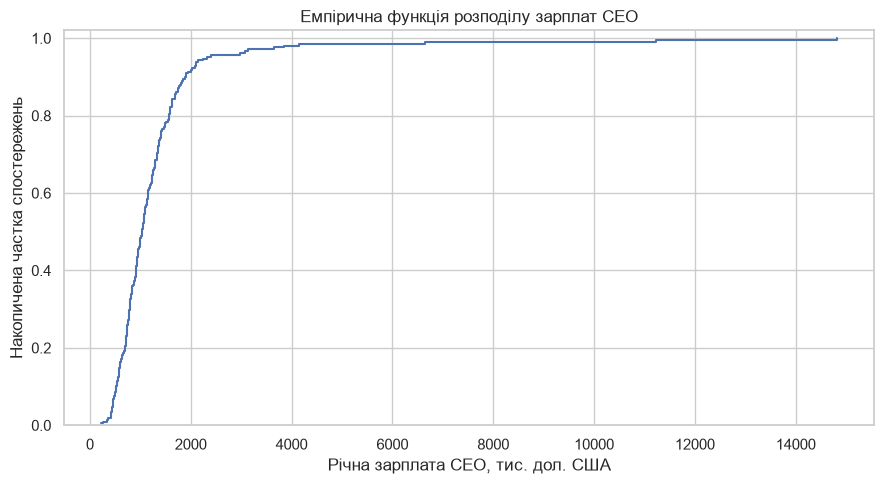

In [4]:
# Перетворюємо Series у масив NumPy
salary_values = salary.to_numpy()

# Сортуємо зарплати від найменшої до найбільшої
salary_sorted = np.sort(salary_values)

# Для кожного відсортованого значення визначаємо накопичену частку:
# 1/n, 2/n, ..., n/n
ecdf_y = np.arange(1, n + 1) / n


# --- Квантилі ---

# Використовуємо означення квантиля з лекції:
# якщо np не ціле — беремо наступне впорядковане значення;
# якщо np ціле — усереднюємо два сусідні значення.
q10, q90 = np.quantile(
    salary_values,
    [0.10, 0.90],
    method="averaged_inverted_cdf"
)


# --- Значення ECDF ---

# Частка CEO із зарплатою <= 1000 тис. дол. США
F_1000 = np.mean(salary_values <= 1000)

# Частка CEO із зарплатою <= 2500 тис. дол. США
F_2500 = np.mean(salary_values <= 2500)

# Частка CEO із зарплатою > 2500 тис. дол. США
above_2500 = 1 - F_2500


# --- Виведення результатів ---

print(f"F^(-1)(0.1) = {q10:.2f} тис. дол. США")
print(f"F^(-1)(0.9) = {q90:.2f} тис. дол. США")
print(f"F(1000) = {F_1000:.4f} ({F_1000 * 100:.2f}%)")
print(f"1 - F(2500) = {above_2500:.4f} ({above_2500 * 100:.2f}%)")


# --- Побудова ECDF ---

plt.figure(figsize=(9, 5))

plt.step(
    salary_sorted,
    ecdf_y,
    where="post"
)

plt.title("Емпірична функція розподілу зарплат CEO")
plt.xlabel("Річна зарплата CEO, тис. дол. США")
plt.ylabel("Накопичена частка спостережень")

plt.ylim(0, 1.02)
plt.grid(True)

plt.tight_layout()
plt.show()

### Інтерпретація

- **$\hat F^{-1}(0.1)=525$ тис. дол. США:** приблизно 10% CEO у вибірці мають річну зарплату не більше **525 тис. дол. США**.

- **$\hat F^{-1}(0.9)=1900$ тис. дол. США:** приблизно 90% CEO мають річну зарплату не більше **1900 тис. дол. США**, а приблизно 10% — більше.

- **$\hat F(1000)=0.4785$:** приблизно **47.85%** CEO у вибірці мають річну зарплату не більше **1000 тис. дол. США (1 млн дол. США)**.

- **$1-\hat F(2500)=0.0431$:** приблизно **4.31%** CEO мають річну зарплату більше **2500 тис. дол. США (2.5 млн дол. США)**.

Графік ECDF швидко зростає в області нижчих зарплат і далі зростає значно повільніше. Це означає, що більшість зарплат зосереджена у нижчому діапазоні, а дуже високі зарплати зустрічаються рідко.


## Частина 1(в). Гістограма та діаграма розмаху

Побудуйте гістограму та діаграму розмаху для `salary` зі стандартними налаштуваннями `matplotlib` або `seaborn`. Поясніть, як інтерпретується площа прямокутника гістограми з обраним типом нормування. Пов'яжіть елементи діаграми розмаху з обчисленими вище мірами положення.


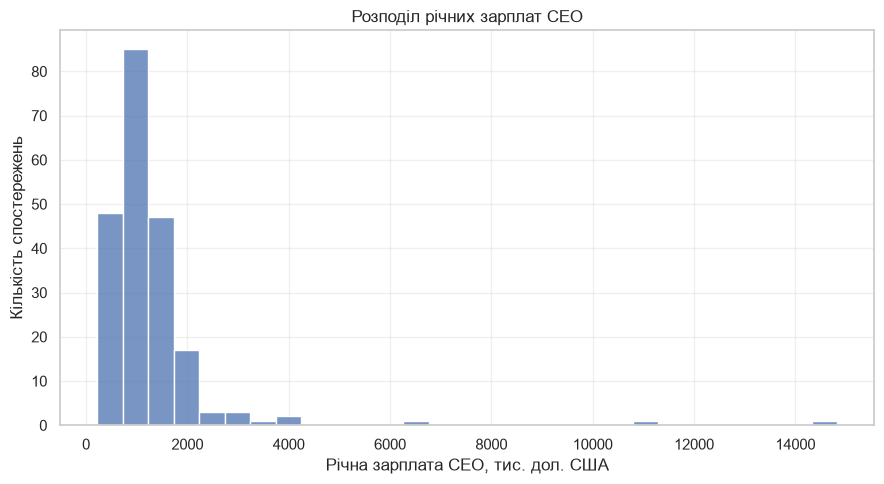

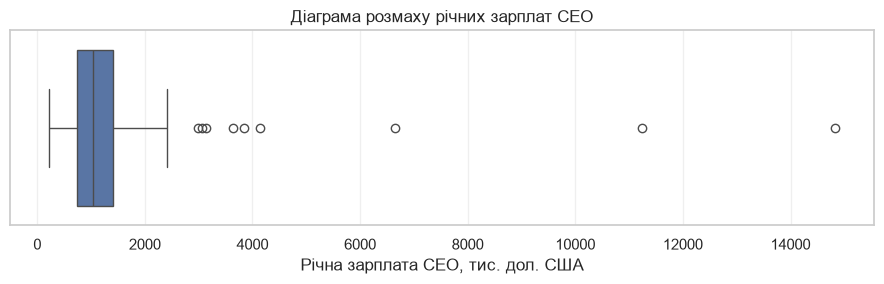

In [5]:
# --- Гістограма ---

plt.figure(figsize=(9, 5))

sns.histplot(salary)

plt.title("Розподіл річних зарплат CEO")
plt.xlabel("Річна зарплата CEO, тис. дол. США")
plt.ylabel("Кількість спостережень")
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


# --- Діаграма розмаху ---

plt.figure(figsize=(9, 3))

sns.boxplot(
    x=salary
)

plt.title("Діаграма розмаху річних зарплат CEO")
plt.xlabel("Річна зарплата CEO, тис. дол. США")
plt.grid(True, axis="x", alpha=0.3)

plt.tight_layout()
plt.show()

### Інтерпретація

Гістограма показує, що більшість зарплат CEO зосереджена приблизно в діапазоні до 2000 тис. дол. США. Водночас є невелика кількість дуже високих зарплат, через що розподіл має довгий правий хвіст.

За стандартних налаштувань `sns.histplot()` висота стовпчика показує кількість спостережень у відповідному інтервалі. Площа прямокутника дорівнює цій кількості, помноженій на ширину інтервалу. Оскільки тут інтервали однакової ширини, площі пропорційні кількостям спостережень. Щоб отримати частку спостережень, потрібно поділити площу на ширину інтервалу та загальну кількість спостережень.

Діаграма розмаху узгоджується з раніше обчисленими показниками:
- нижній квартиль $Q_1 = 736$ тис. дол. США;
- медіана = $1039$ тис. дол. США;
- верхній квартиль $Q_3 = 1407$ тис. дол. США.

Отже, центральні 50% зарплат знаходяться приблизно між **736** та **1407 тис. дол. США**.

На boxplot також видно кілька значень значно вище основної частини вибірки. Вони позначені як потенційні викиди. Саме такі дуже високі зарплати пояснюють довгий правий хвіст гістограми і те, що середнє значення зарплати вище за медіану.

## Частина 1(г). Форма розподілу

Зробіть висновок про розподіл `salary`. Чи залишаються доречними обчислені вище міри положення? Обчисліть коефіцієнт асиметрії Фішера–Пірсона та поясніть його значення.


In [6]:
# Емпіричне стандартне відхилення.
# ddof=0 означає, що у формулі ділимо на n.
salary_std_empirical = salary.std(ddof=0)

# Коефіцієнт асиметрії Фішера–Пірсона:
# для кожного спостереження знаходимо відхилення від середнього,
# ділимо на стандартне відхилення, підносимо до куба
# і беремо середнє цих значень.
salary_skewness = np.mean(
    ((salary - mean_salary) / salary_std_empirical) ** 3
)

print(f"Коефіцієнт асиметрії Фішера–Пірсона = {salary_skewness:.3f}")

# Перевірка через scipy: bias=True відповідає формулі
# через емпіричні центральні моменти з дільником n.
salary_skewness_scipy = stats.skew(salary, bias=True)

print(f"Перевірка через scipy = {salary_skewness_scipy:.3f}")

Коефіцієнт асиметрії Фішера–Пірсона = 6.855
Перевірка через scipy = 6.855


### Інтерпретація

Коефіцієнт асиметрії Фішера–Пірсона дорівнює **6.855**. Він є додатним і досить великим, тому розподіл зарплат має **сильну правосторонню асиметрію**.

Це узгоджується з гістограмою та boxplot: більшість зарплат знаходяться у значно нижчому діапазоні, але є кілька дуже високих значень, які утворюють довгий правий хвіст.

Через ці високі зарплати середнє значення (**1281.12 тис. дол. США**) помітно вище за медіану (**1039 тис. дол. США**). Тому для опису типового рівня зарплати медіана та 5%-усічене середнє є більш надійними, ніж звичайне середнє.

## Частина 1(ґ). Вибір інтервалів гістограми

Перевірте й коротко опишіть правило, за яким використана бібліотека у встановленій версії визначає стандартну ширину інтервалу або кількість стовпчиків гістограми. Побудуйте гістограми з `bins=150` та `bins=3`. Поясніть, що показує або приховує надмірна деталізація та надмірне узагальнення.


In [7]:
import inspect

# Перевіряємо версії бібліотек,
# оскільки поведінка може залежати від встановленої версії.
print("seaborn version:", sns.__version__)
print("numpy version:", np.__version__)

# Дивимося стандартне значення параметра bins у sns.histplot
print(inspect.signature(sns.histplot))

seaborn version: 0.13.2
numpy version: 2.5.3
(data=None, *, x=None, y=None, hue=None, weights=None, stat='count', bins='auto', binwidth=None, binrange=None, discrete=None, cumulative=False, common_bins=True, common_norm=True, multiple='layer', element='bars', fill=True, shrink=1, kde=False, kde_kws=None, line_kws=None, thresh=0, pthresh=None, pmax=None, cbar=False, cbar_ax=None, cbar_kws=None, palette=None, hue_order=None, hue_norm=None, color=None, log_scale=None, legend=True, ax=None, **kwargs)


In [8]:
# Межі інтервалів, які NumPy вибирає автоматично
auto_bin_edges = np.histogram_bin_edges(salary, bins="auto")

# Кількість інтервалів на 1 менша за кількість їхніх меж
auto_bin_count = len(auto_bin_edges) - 1

print(f"Автоматично вибрана кількість інтервалів: {auto_bin_count}")

Автоматично вибрана кількість інтервалів: 29


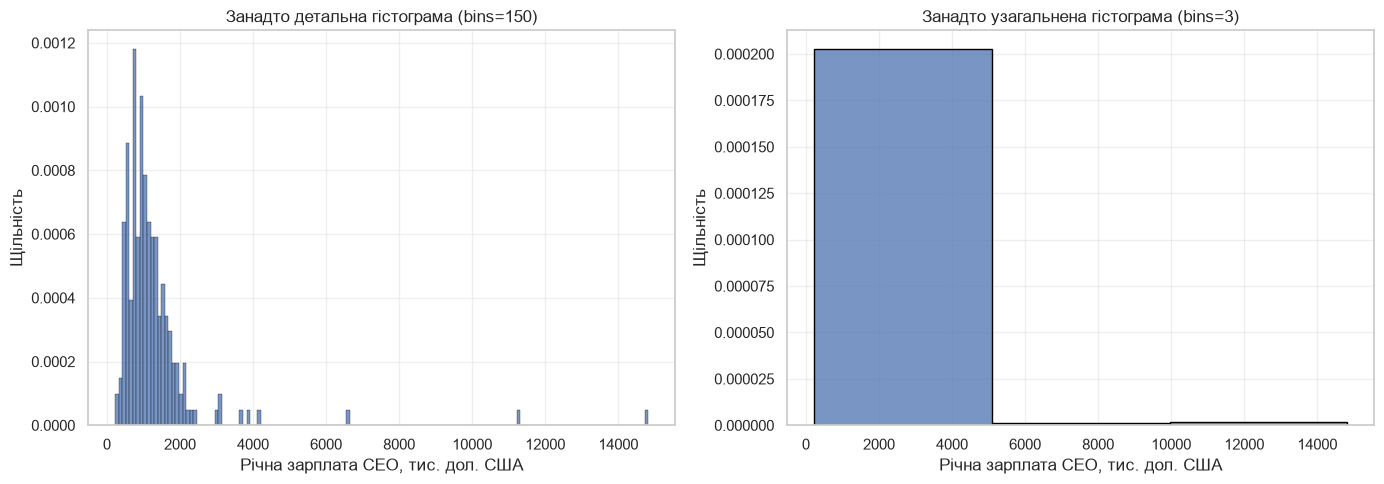

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# --- Занадто детальна гістограма ---

sns.histplot(
    salary,
    bins=150,
    stat="density",
    edgecolor="black",
    ax=axes[0]
)

axes[0].set_title("Занадто детальна гістограма (bins=150)")
axes[0].set_xlabel("Річна зарплата CEO, тис. дол. США")
axes[0].set_ylabel("Щільність")
axes[0].grid(True, alpha=0.3)


# --- Занадто узагальнена гістограма ---

sns.histplot(
    salary,
    bins=3,
    stat="density",
    edgecolor="black",
    ax=axes[1]
)

axes[1].set_title("Занадто узагальнена гістограма (bins=3)")
axes[1].set_xlabel("Річна зарплата CEO, тис. дол. США")
axes[1].set_ylabel("Щільність")
axes[1].grid(True, alpha=0.3)


plt.tight_layout()
plt.show()

### Інтерпретація

За стандартних налаштувань `sns.histplot()` використовує `bins="auto"`.
У нашому випадку автоматично було вибрано **29 інтервалів**.

Режим `auto` у NumPy порівнює правило Стерджеса та правило Фрідмана–Діаконіса
і використовує більш деталізований варіант. Мета такого автоматичного вибору —
отримати достатньо детальну гістограму, але не перевантажити її випадковими
коливаннями.

При `bins=150` гістограма стає занадто детальною: з'являється багато дуже вузьких
стовпчиків, частина з яких містить лише одне або кілька спостережень. Через це
графік виглядає шумним і загальну форму розподілу бачити складніше.

При `bins=3` гістограма, навпаки, занадто узагальнена. Майже всі звичайні зарплати
потрапляють в один широкий інтервал, тому ми втрачаємо інформацію про те,
як саме зарплати розподілені в основній частині вибірки.

Отже, кількість інтервалів суттєво впливає на вигляд гістограми:
занадто велика кількість показує надмірний шум, а занадто мала приховує важливу
структуру даних. Автоматично вибрані 29 інтервалів дають значно корисніший
компроміс для цієї вибірки.

## Частина 1(д). Логарифмування заробітної плати

Розгляньте натуральний логарифм $\ln(\mathrm{salary})$. Побудуйте гістограму та діаграму розмаху й порівняйте їх із графіками вихідної змінної. Обчисліть середнє та медіану логарифмованих значень. Зробіть висновки про симетричність розподілу та надайте економічну інтерпретацію результатів.


In [10]:
# Створюємо логарифмовані значення зарплати.
# Початкову змінну salary не змінюємо.
log_salary = np.log(salary)

# Середнє та медіана логарифмованих зарплат
log_mean_salary = log_salary.mean()
log_median_salary = log_salary.median()

# Коефіцієнт асиметрії після логарифмування.
# Використовуємо той самий підхід, що й для початкових зарплат.
log_salary_std_empirical = log_salary.std(ddof=0)

log_salary_skewness = np.mean(
    ((log_salary - log_mean_salary) / log_salary_std_empirical) ** 3
)

print(f"Середнє ln(salary) = {log_mean_salary:.3f}")
print(f"Медіана ln(salary) = {log_median_salary:.3f}")
print(f"Коефіцієнт асиметрії ln(salary) = {log_salary_skewness:.3f}")
# Повертаємо середнє логарифмів до грошової шкали.
geometric_mean_salary = np.exp(log_mean_salary)
print(f"Геометричне середнє зарплати = {geometric_mean_salary:.2f} тис. дол. США")


Середнє ln(salary) = 6.950
Медіана ln(salary) = 6.946
Коефіцієнт асиметрії ln(salary) = 0.880
Геометричне середнє зарплати = 1043.55 тис. дол. США


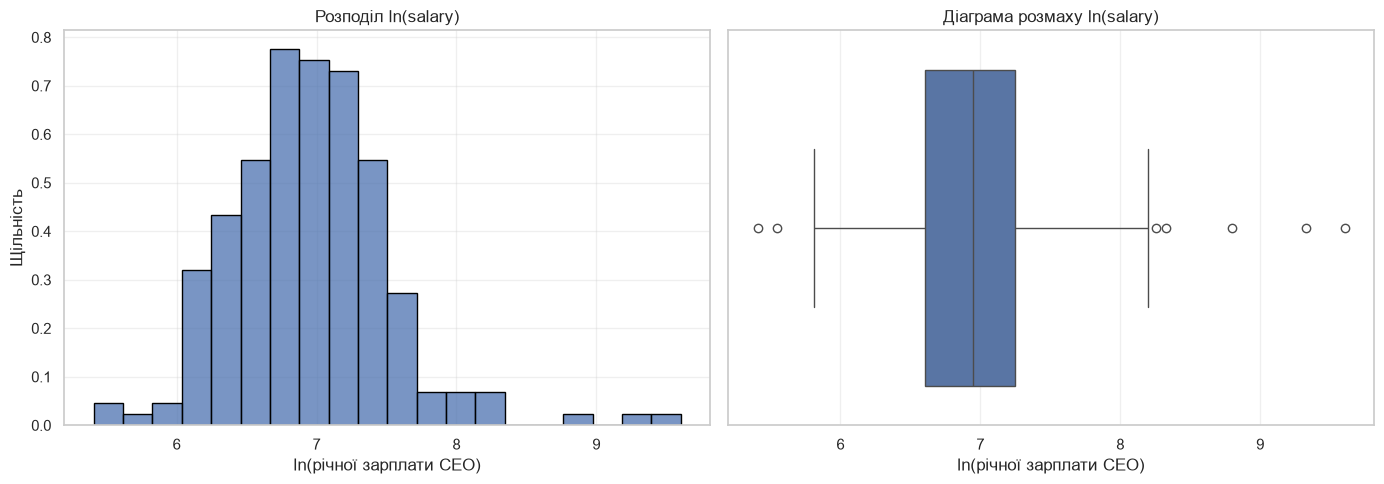

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))


# --- Гістограма логарифмованої зарплати ---

sns.histplot(
    log_salary,
    bins="auto",
    stat="density",
    edgecolor="black",
    ax=axes[0]
)

axes[0].set_title("Розподіл ln(salary)")
axes[0].set_xlabel("ln(річної зарплати CEO)")
axes[0].set_ylabel("Щільність")
axes[0].grid(True, alpha=0.3)


# --- Діаграма розмаху логарифмованої зарплати ---

sns.boxplot(
    x=log_salary,
    ax=axes[1]
)

axes[1].set_title("Діаграма розмаху ln(salary)")
axes[1].set_xlabel("ln(річної зарплати CEO)")
axes[1].grid(True, axis="x", alpha=0.3)


plt.tight_layout()
plt.show()

### Інтерпретація

Після логарифмування розподіл зарплат став значно більш симетричним. Це видно і на гістограмі, і за коефіцієнтом асиметрії: він зменшився з **6.855** до **0.880**.

Коефіцієнт асиметрії все ще додатний, тому невелика правостороння асиметрія залишається, але вона вже набагато слабша.

Середнє значення `ln(salary)` дорівнює **6.950**, а медіана — **6.946**. Вони майже однакові, що також показує, що після логарифмування розподіл став ближчим до симетричного.

Якщо піднести $e$ до середнього логарифма зарплати, отримаємо геометричне середнє — **1043.55 тис. дол. США**. Воно описує середній рівень зарплати на логарифмічній шкалі та менше залежить від дуже великих зарплат, ніж звичайне середнє.

Якщо повернути медіану назад до початкової шкали:

$$
e^{6.946} \approx 1039
$$

тис. дол. США, що відповідає медіані початкових зарплат.

Логарифмування стискає дуже великі значення зарплат, тому окремі дуже високооплачувані CEO вже не так сильно розтягують правий хвіст розподілу.

## Частина 2(а). Кореляція Пірсона

Ми припускаємо, що заробітна плата CEO та інші змінні компанії пов’язані між собою. Обчисліть коефіцієнти кореляції Пірсона та зобразіть їх у вигляді теплової карти (кореляційної карти). Обговоріть силу та напрямок кореляцій.


,salary,pcsalary,age,sales,roe
salary,1.000,0.009,-0.110,0.120,0.115
pcsalary,0.009,1.000,0.036,0.017,0.087
age,-0.110,0.036,1.000,0.080,-0.027
sales,0.120,0.017,0.080,1.000,-0.055
roe,0.115,0.087,-0.027,-0.055,1.000


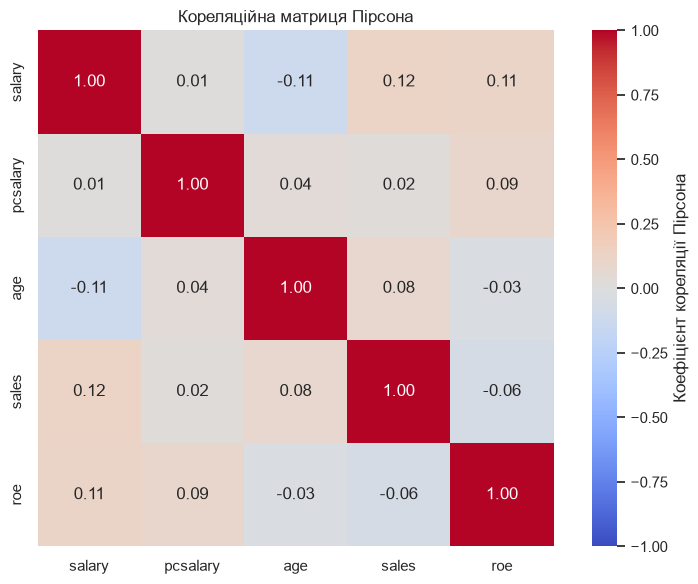

In [12]:
# Змінні, між якими аналізуємо кореляцію.
# Використовуємо початкові значення без логарифмування.
analysis_columns = ["salary", "pcsalary", "age", "sales", "roe"]

# Обчислюємо матрицю коефіцієнтів кореляції Пірсона.
# Кожна комірка показує кореляцію між відповідною парою змінних.
pearson_corr = df[analysis_columns].corr(method="pearson")

# Виводимо числові значення для точного перегляду.
display(pearson_corr.round(3))


# --- Теплова карта кореляцій ---

plt.figure(figsize=(8, 6))

sns.heatmap(
    pearson_corr,
    annot=True,          # показуємо числове значення у кожній комірці
    fmt=".2f",           # округлення до двох знаків
    vmin=-1,
    vmax=1,
    center=0,
    cmap="coolwarm",
    square=True,
    cbar_kws={"label": "Коефіцієнт кореляції Пірсона"}
)

plt.title("Кореляційна матриця Пірсона")
plt.tight_layout()
plt.show()

### Інтерпретація 

Усі отримані коефіцієнти кореляції Пірсона за модулем є дуже малими: найбільше значення становить лише близько **0.12**. Отже, у цих даних немає помітних сильних лінійних зв’язків між розглянутими змінними.

Для `salary`:

- `salary` і `sales`: $r \approx 0.12$ — дуже слабкий позитивний лінійний зв’язок;
- `salary` і `roe`: $r \approx 0.11$ — дуже слабкий позитивний зв’язок;
- `salary` і `age`: $r \approx -0.11$ — дуже слабкий негативний зв’язок;
- `salary` і `pcsalary`: $r \approx 0.01$ — практично відсутній лінійний зв’язок.

Інші пари змінних також мають коефіцієнти, близькі до нуля, тому сильних лінійних залежностей між ними не видно.

Значення **1.00** на головній діагоналі означають кореляцію кожної змінної із самою собою і окремо не інтерпретуються.

Отже, за кореляцією Пірсона жодна з розглянутих змінних не має сильного лінійного зв’язку із зарплатою CEO.

## Частина 2(б). Діаграми розсіювання

Побудуйте діаграми розсіювання (матричний графік `pairplot` у Python). Зробіть висновок, чи доречні тут лінійні коефіцієнти кореляції. Тепер обчисліть кореляції Спірмена та побудуйте для них теплову карту. Порівняйте отримані результати з результатами Пірсона.


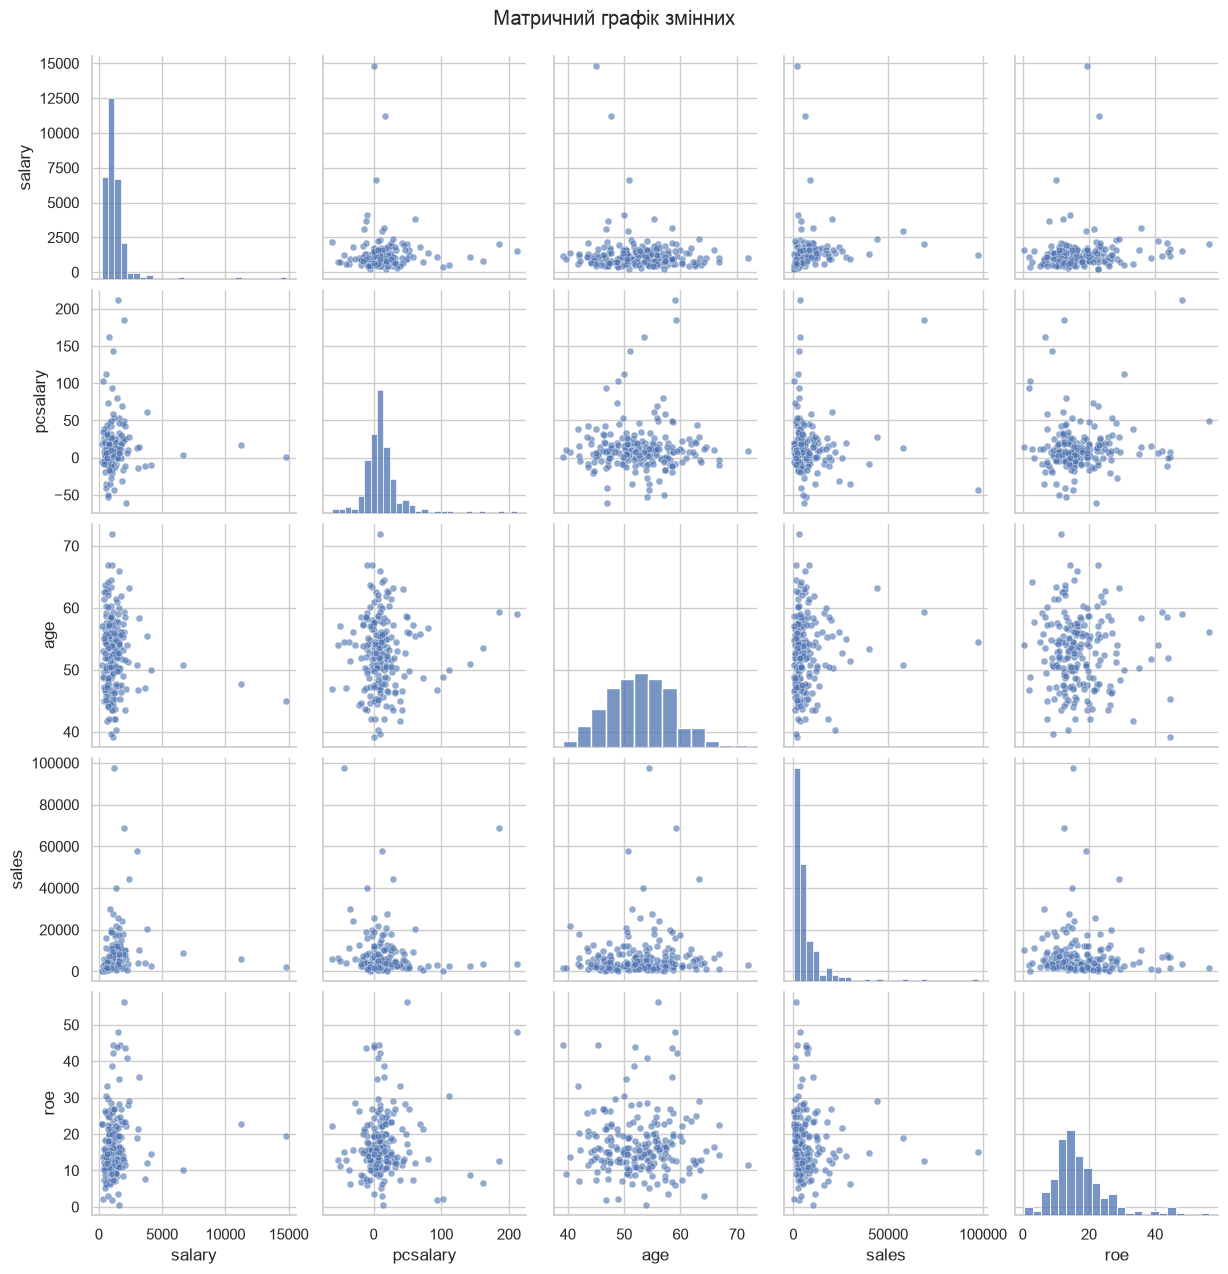

In [13]:
# Будуємо матрицю діаграм розсіювання для всіх пар змінних.
# На діагоналі показуються розподіли окремих змінних.
sns.pairplot(
    df[analysis_columns],
    diag_kind="hist",
    plot_kws={
        "alpha": 0.6,  # робимо точки трохи прозорими
        "s": 25        # розмір точок
    }
)

plt.suptitle(
    "Матричний графік змінних",
    y=1.02
)

plt.show()

,salary,pcsalary,age,sales,roe
salary,1.000,0.076,-0.030,0.528,0.206
pcsalary,0.076,1.000,-0.003,-0.074,0.058
age,-0.030,-0.003,1.000,0.063,-0.017
sales,0.528,-0.074,0.063,1.000,-0.171
roe,0.206,0.058,-0.017,-0.171,1.000


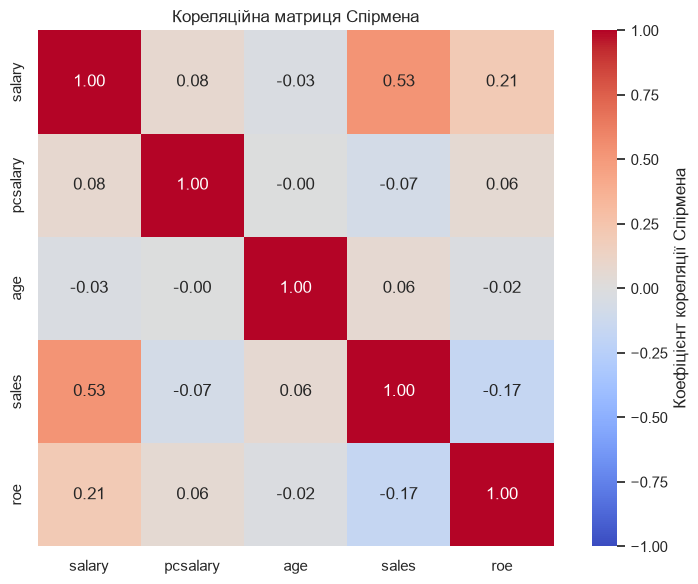

In [14]:
# Обчислюємо матрицю кореляцій Спірмена.
# Метод працює з рангами значень, а не безпосередньо з їх величинами.
spearman_corr = df[analysis_columns].corr(method="spearman")

# Виводимо точні числові значення
display(spearman_corr.round(3))


# --- Теплова карта Спірмена ---

plt.figure(figsize=(8, 6))

sns.heatmap(
    spearman_corr,
    annot=True,
    fmt=".2f",
    vmin=-1,
    vmax=1,
    center=0,
    cmap="coolwarm",
    square=True,
    cbar_kws={"label": "Коефіцієнт кореляції Спірмена"}
)

plt.title("Кореляційна матриця Спірмена")
plt.tight_layout()
plt.show()

In [15]:
# Порівнюємо Pearson і Spearman для зв'язків із salary
salary_corr_comparison = pd.DataFrame({
    "Pearson": pearson_corr["salary"],
    "Spearman": spearman_corr["salary"]
})

display(salary_corr_comparison.round(3))

,Pearson,Spearman
salary,1.000,1.000
pcsalary,0.009,0.076
age,-0.110,-0.030
sales,0.120,0.528
roe,0.115,0.206


### Інтерпретація

На `pairplot` видно, що для більшості пар змінних немає чіткої лінійної залежності. Крім того, у `salary` та `sales` є великі викиди і сильна правостороння асиметрія. Тому коефіцієнт Пірсона не завжди добре описує зв'язки в цих даних.

Найбільша різниця спостерігається для `salary` і `sales`:

- Пірсон: $r = 0.120$;
- Спірмен: $\rho_s = 0.528$.

За Пірсоном лінійний зв'язок виглядає дуже слабким, але Спірмен показує помітний позитивний монотонний зв'язок: компанії з більшими продажами загалом мають тенденцію платити CEO більше. Різниця виникає тому, що зв'язок не обов'язково є лінійним, а великі значення сильніше впливають на коефіцієнт Пірсона.

Для `salary` і `roe` також бачимо дещо більшу кореляцію Спірмена:
$0.206$ проти $0.115$ у Пірсона, але зв'язок все одно залишається слабким.

Для `salary` і `pcsalary` обидва коефіцієнти близькі до нуля
($0.009$ і $0.076$), тому помітного зв'язку немає.

Для `salary` і `age` обидва коефіцієнти також близькі до нуля
($-0.110$ і $-0.030$). При цьому `age` у цій роботі є змодельованою змінною, тому цей результат не слід трактувати як реальну економічну закономірність.

Отже, кореляція Спірмена виявляє деякі зв'язки, які Пірсон майже не показує, особливо між `salary` і `sales`. Для цих даних одного коефіцієнта Пірсона недостатньо, оскільки частина залежностей може бути монотонною, але не лінійною, а також присутні сильні викиди.

## Частина 2(в)

Поясніть своїми словами концептуальну різницю між двома коефіцієнтами кореляції та пов’яжіть її з лінійною і монотонною залежністю.

### Інтерпретація

Коефіцієнт кореляції **Пірсона** показує силу і напрямок **лінійного зв'язку** між двома змінними. Тобто він добре працює, коли залежність між змінними приблизно можна описати прямою лінією.

Коефіцієнт кореляції **Спірмена** працює з рангами значень і показує силу **монотонного зв'язку**. Монотонний зв'язок означає, що зі зростанням однієї змінної інша загалом або зростає, або спадає, але ця залежність не обов'язково має бути лінійною.

Тому Пірсон може показувати слабку кореляцію, якщо залежність є нелінійною. Спірмен у такому випадку може краще виявити загальну тенденцію.

У наших даних це добре видно на зв'язку між `salary` і `sales`: кореляція Пірсона дорівнює приблизно **0.12**, а Спірмена — **0.53**. Отже, між продажами компанії та зарплатою CEO є помітна позитивна монотонна тенденція, але вона погано описується прямою лінією.

## Частина 2(г). Вікові підвибірки

Розгляньте дві підвибірки: CEO молодші за 50 років і старші за 50 років. Побудуйте для обох підвибірок накладені одна на одну гістограми / емпіричні функції розподілу (`ecdf`) та обговоріть результати. Чого ми можемо навчитися з відповідних мір положення та розсіювання?


In [16]:
# Формуємо дві підвибірки зарплат за віком CEO.
salary_under_50 = df.loc[df["age"] < 50, "salary"].dropna()
salary_over_50 = df.loc[df["age"] > 50, "salary"].dropna()

print(f"CEO молодші за 50 років: {len(salary_under_50)}")
print(f"CEO старші за 50 років: {len(salary_over_50)}")
print(f"CEO віком рівно 50 років: {(df['age'] == 50).sum()}")


# --- Міри положення та розсіювання ---

age_group_summary = pd.DataFrame({
    "Молодші за 50": [
        salary_under_50.mean(),
        salary_under_50.median(),
        salary_under_50.std(),
        salary_under_50.quantile(0.25),
        salary_under_50.quantile(0.75),
        salary_under_50.quantile(0.75) - salary_under_50.quantile(0.25)
    ],
    "Старші за 50": [
        salary_over_50.mean(),
        salary_over_50.median(),
        salary_over_50.std(),
        salary_over_50.quantile(0.25),
        salary_over_50.quantile(0.75),
        salary_over_50.quantile(0.75) - salary_over_50.quantile(0.25)
    ]
}, index=[
    "Середнє",
    "Медіана",
    "Стандартне відхилення",
    "Q1",
    "Q3",
    "IQR"
])

display(age_group_summary.round(2))

CEO молодші за 50 років: 66
CEO старші за 50 років: 143
CEO віком рівно 50 років: 0


,Молодші за 50,Старші за 50
Середнє,1488.14,1185.57
Медіана,1013.50,1045.00
Стандартне відхилення,2192.39,727.58
Q1,723.00,775.00
Q3,1332.50,1450.00
IQR,609.50,675.00


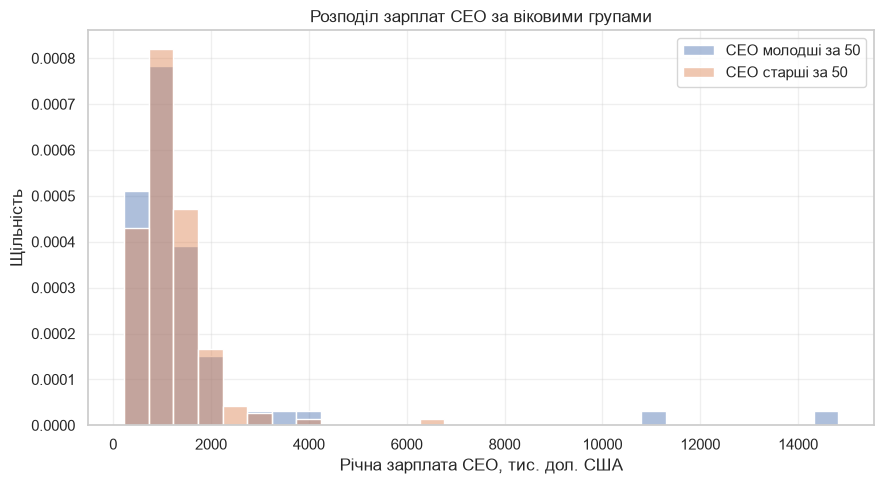

In [17]:
# Спільні межі інтервалів для обох підвибірок.
# Завдяки цьому стовпчики двох гістограм відповідають однаковим діапазонам зарплат.
age_group_bin_edges = np.histogram_bin_edges(
    pd.concat([salary_under_50, salary_over_50]),
    bins="auto"
)

plt.figure(figsize=(9, 5))

sns.histplot(
    salary_under_50,
    bins=age_group_bin_edges,
    stat="density",
    alpha=0.45,
    label="CEO молодші за 50"
)

sns.histplot(
    salary_over_50,
    bins=age_group_bin_edges,
    stat="density",
    alpha=0.45,
    label="CEO старші за 50"
)

plt.title("Розподіл зарплат CEO за віковими групами")
plt.xlabel("Річна зарплата CEO, тис. дол. США")
plt.ylabel("Щільність")
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

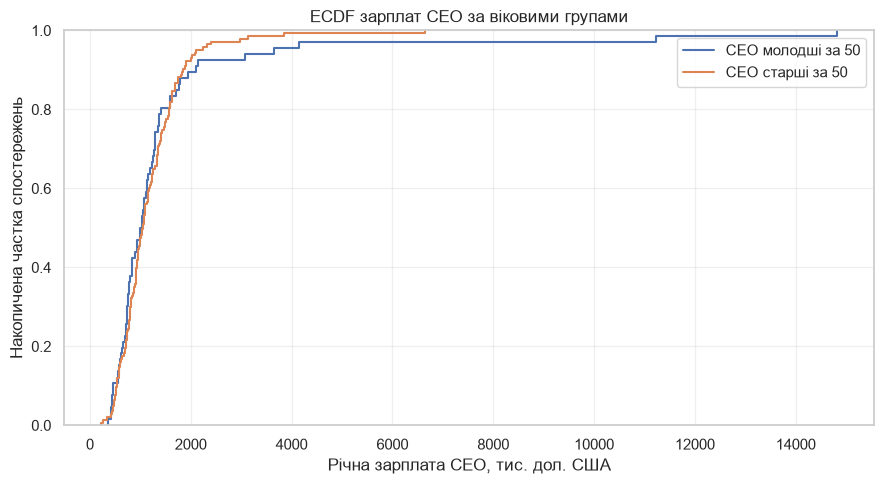

In [18]:
plt.figure(figsize=(9, 5))

sns.ecdfplot(
    salary_under_50,
    label="CEO молодші за 50"
)

sns.ecdfplot(
    salary_over_50,
    label="CEO старші за 50"
)

plt.title("ECDF зарплат CEO за віковими групами")
plt.xlabel("Річна зарплата CEO, тис. дол. США")
plt.ylabel("Накопичена частка спостережень")
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

### Інтерпретація

У вибірці є 66 CEO молодших за 50 років і 143 CEO старших за 50 років. CEO віком рівно 50 років у вибірці немає.

Медіани зарплат у двох групах дуже близькі:

- молодші за 50: **1013.50 тис. дол. США**;
- старші за 50: **1045.00 тис. дол. США**.

Отже, типовий рівень зарплати в обох вікових групах є приблизно однаковим.

Середнє значення для молодших CEO є вищим:

- молодші за 50: **1488.14 тис. дол. США**;
- старші за 50: **1185.57 тис. дол. США**.

Але це пояснюється кількома дуже великими зарплатами у групі молодших CEO. Це також видно зі значно більшого стандартного відхилення: **2192.39** проти **727.58** тис. дол. США.

При цьому міжквартильний розмах досить схожий:

- молодші за 50: **IQR = 609.50**;
- старші за 50: **IQR = 675.00**.

Тобто центральні 50% зарплат у двох групах мають подібний розкид, а велика різниця у стандартному відхиленні виникає переважно через дуже високі окремі значення у групі молодших CEO.

Накладені гістограми та ECDF також показують, що основна частина двох розподілів сильно перекривається. Тому чіткої різниці у типовому рівні зарплати між цими двома віковими групами не видно.

Водночас `age` у цій роботі є штучно змодельованою змінною, тому ці результати не слід трактувати як реальний економічний висновок про вплив віку CEO на зарплату.

## Частина 3(а). Таблиці спряженості

Визначте вікові групи $A_1$: `age < 55`, $A_2$: `age >= 55` та групи заробітної плати $S_1$: `salary < 700`, $S_2$: `700 <= salary < 1300`, $S_3$: `salary >= 1300`. Заробітну плату задано в тисячах доларів США.

За допомогою `pd.crosstab` побудуйте таблиці абсолютних та відносних частот розміром $2\times3$: рядки — $A_1,A_2$, стовпці — $S_1,S_2,S_3$. Відносні частоти обчислюйте від загальної кількості спостережень; додайте підсумки.


In [19]:
# --- Групи за рівнем зарплати ---

# right=False означає, що інтервали мають вигляд:
# [нижня межа, верхня межа)
# Тобто 700 потрапляє у S2, а 1300 — у S3.
salary_group = pd.cut(
    df["salary"],
    bins=[-np.inf, 700, 1300, np.inf],
    labels=["S1: <700", "S2: 700–1299", "S3: ≥1300"],
    right=False
)


# --- Групи за віком ---

# A1: age < 55
# A2: age >= 55
age_group = pd.cut(
    df["age"],
    bins=[-np.inf, 55, np.inf],
    labels=["A1: <55", "A2: ≥55"],
    right=False
)


# --- Абсолютні частоти ---

# Кожна комірка показує кількість CEO,
# які одночасно належать до відповідної вікової
# та зарплатної групи.
contingency_abs = pd.crosstab(
    age_group,
    salary_group,
    margins=True,
    margins_name="Разом"
)

print("Абсолютні частоти:")
display(contingency_abs)


# --- Відносні частоти ---

# normalize="all" ділить кожну комірку
# на загальну кількість спостережень.
# Тобто отримуємо частку від усієї вибірки.
contingency_rel = pd.crosstab(
    age_group,
    salary_group,
    normalize="all",
    margins=True,
    margins_name="Разом"
)

print("Відносні частоти:")
display(contingency_rel.round(3))

Абсолютні частоти:


salary,S1: <700,S2: 700–1299,S3: ≥1300,Разом
age,,,,
A1: <55,27,66,44,137
A2: ≥55,15,35,22,72
Разом,42,101,66,209


Відносні частоти:


salary,S1: <700,S2: 700–1299,S3: ≥1300,Разом
age,,,,
A1: <55,0.129,0.316,0.211,0.656
A2: ≥55,0.072,0.167,0.105,0.344
Разом,0.201,0.483,0.316,1.000


## Частина 3(б). Інтерпретація частот

Дайте економічну та статистичну інтерпретацію $n_{12}$, $h_{12}$, $n_{1\cdot}$ та $h_{1\cdot}$ на основі таблиць.


### Інтерпретація

У таблиці рядки відповідають віковим групам $A_i$, а стовпці — групам зарплати $S_j$.

- $n_{12}=66$ — кількість CEO молодших за 55 років, які мають річну зарплату від 700 включно до 1300 невключно тис. дол. США.

- $h_{12}=0.316$ — частка таких CEO у всій вибірці. Отже, приблизно 31.6% усіх спостережень належать одночасно до груп $A_1$ та $S_2$.

- $n_{1\cdot}=137$ — загальна кількість CEO молодших за 55 років незалежно від рівня їхньої зарплати.

- $h_{1\cdot}=0.656$ — частка CEO молодших за 55 років у всій вибірці, тобто приблизно 65.6%.

## Частина 3(в). Залежність якісних ознак

Обчисліть відповідну міру залежності якісних ознак: коефіцієнт Крамера $V$ або статистику критерію Пірсона $\chi^2$. Поясніть результат і зробіть висновок про зв'язок віку та заробітної плати, враховуючи синтетичне походження віку.


In [20]:
# Беремо лише основну таблицю 2×3 без підсумкових
# рядка та стовпця "Разом".
contingency_core = contingency_abs.iloc[:-1, :-1]

# χ²-критерій Пірсона на незалежність.
chi2_stat, p_value, degrees_of_freedom, expected_freq = stats.chi2_contingency(
    contingency_core
)

print(f"χ² = {chi2_stat:.3f}")
print(f"p-value = {p_value:.4f}")
print(f"Ступені свободи = {degrees_of_freedom}")

# Очікувані частоти за умови незалежності
expected_table = pd.DataFrame(
    expected_freq,
    index=contingency_core.index,
    columns=contingency_core.columns
)

print("Очікувані частоти при незалежності:")
display(expected_table.round(2))

χ² = 0.068
p-value = 0.9666
Ступені свободи = 2
Очікувані частоти при незалежності:


salary,S1: <700,S2: 700–1299,S3: ≥1300
age,,,
A1: <55,27.53,66.21,43.26
A2: ≥55,14.47,34.79,22.74


In [21]:
# Розміри таблиці
rows, cols = contingency_core.shape

# Коефіцієнт Крамера V:
# показує силу зв'язку між двома категоріальними ознаками.
cramers_v = np.sqrt(
    chi2_stat
    / (contingency_core.to_numpy().sum() * min(rows - 1, cols - 1))
)

print(f"Коефіцієнт Крамера V = {cramers_v:.3f}")

Коефіцієнт Крамера V = 0.018


### Інтерпретація

Для перевірки зв'язку між віковою групою CEO та категорією зарплати використано $\chi^2$-критерій незалежності Пірсона.

Отримано:

$$
\chi^2 = 0.068,
\qquad
p\text{-value} = 0.9666.
$$

Оскільки $p\text{-value} > 0.05$, немає підстав вважати, що вікова група та категорія зарплати пов'язані між собою.

Очікувані частоти при незалежності дуже близькі до фактичних частот у таблиці, що також вказує на відсутність помітної залежності.

Коефіцієнт Крамера становить:

$$
V = 0.018.
$$

Це значення дуже близьке до нуля, тому сила зв'язку між віковою групою та рівнем зарплати є практично відсутньою.

Важливо, що змінна `age` у цій роботі була синтетично згенерована, тому цей результат не слід трактувати як реальний економічний висновок про вплив віку CEO на його зарплату.